# CIFAR - 10


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10

(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(train_images.shape, test_images.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


# Image flatten



In [48]:
test_images_raw = test_images.copy()

# flatten train
train_images = train_images.reshape(len(train_images), -1)
train_labels = train_labels.reshape(-1)
# flatten test
test_images = test_images.reshape(len(test_images), -1)
test_labels = test_labels.reshape(-1)

X_train = train_images.astype(np.float64) / 255.0
X_test = test_images.astype(np.float64) / 255.0

y_train, y_test = train_labels, test_labels
print(X_train.shape, X_test.shape)

(50000, 3072) (10000, 3072)


linear function
weight W = random[10,3072]

In [69]:
SEED = 42
np.random.seed(SEED) # seed fix

W = 0.01* np.random.randn(10, 3072)
b = np.zeros(10)

def linear_pred(X, W, b):
    return X @ W.T + b

# example
idx = np.arange(10)
X_ex, y_ex = X_test[idx], y_test[idx]

#label predict
pred = linear_pred(X_ex, W, b)
label = pred.argmax(axis=1)

df_scores = pd.DataFrame(pred, columns=class_names).round(4)
df_scores.insert(0, 'true', [class_names[i] for i in y_ex])
df_scores['pred'] = [class_names[i] for i in label]
print(df_scores.to_string())

         true  airplane  automobile    bird     cat    deer     dog    frog   horse    ship   truck      pred
0         cat    0.4156     -0.4650  0.0233 -0.0342  0.4149  0.3860  0.0355 -0.1464  0.1300 -0.0384  airplane
1        ship    0.4730     -0.4486 -0.2919 -0.5885  0.2668  0.4892 -0.0337 -0.2141  0.0726 -0.5967       dog
2        ship    0.4927     -0.2826 -0.0895 -0.3550  0.2733  0.4315 -0.0580 -0.1561  0.0185 -0.2953  airplane
3    airplane    0.5984     -0.5332 -0.0442 -0.4774  0.2740  0.4589 -0.1272 -0.3330  0.2791 -0.3146  airplane
4        frog    0.3026     -0.5253  0.0410 -0.1516  0.3515  0.4368 -0.1058 -0.1048  0.0282 -0.2250       dog
5        frog    0.4534     -0.3496 -0.0971 -0.0554  0.4419  0.2669 -0.0990 -0.1580  0.2149 -0.1800  airplane
6  automobile    0.3634     -0.4051 -0.0149 -0.1215  0.4284  0.2809 -0.0174 -0.0976  0.1763 -0.2354      deer
7        frog    0.3051     -0.2959 -0.0135 -0.1442  0.4067  0.2919 -0.1131 -0.1222  0.3070 -0.1388      deer
8         

# SVM hinge loss


In [70]:
def svm_loss(pred, y, delta=1.0):
    # multiclass SVM loss
    N = pred.shape[0]
    correct = pred[np.arange(N), y].reshape(-1, 1)
    margins = np.maximum(0, pred - correct + delta)
    margins[np.arange(N), y] = 0
    return margins.sum(axis=1)

losses_svm = svm_loss(pred, y_ex)
print('SVM loss_average:', losses_svm.round(4))
print(' SVM loss_average    :', losses_svm.mean())

SVM loss_average: [10.0633  7.4024  8.7943  3.0045 10.1053 10.4276 13.4076 10.6143 12.1386
 12.4882]
 SVM loss_average    : 9.844600069433953


# Softmax

svm -> probability

In [72]:
def softmax(pred):
    shifted = pred - pred.max(axis=1, keepdims=True)
    e = np.exp(shifted)
    return e / e.sum(axis=1, keepdims=True)

probs = softmax(pred)

# probablity
df_probs = pd.DataFrame(probs, columns=class_names).round(4)
df_probs.insert(0, 'real', [class_names[i] for i in y_ex])
df_probs['model_pred'] = [class_names[i] for i in label]
df_probs['sum'] = probs.sum(axis=1)
print(df_probs.to_string())
print()


comp = pd.DataFrame({'[before softmax]': pred[0], '[after softmax(probability)]': probs[0]}, index=class_names)

print()
print("example")
print(f'real_label: {class_names[y_ex[0]]}, model_pred: {class_names[label[0]]}')
print(comp.round(4).to_string())

         real  airplane  automobile    bird     cat    deer     dog    frog   horse    ship   truck model_pred  sum
0         cat    0.1363      0.0565  0.0920  0.0869  0.1362  0.1323  0.0932  0.0777  0.1024  0.0865   airplane  1.0
1        ship    0.1624      0.0646  0.0756  0.0562  0.1321  0.1651  0.0978  0.0817  0.1088  0.0557        dog  1.0
2        ship    0.1570      0.0723  0.0877  0.0673  0.1261  0.1477  0.0905  0.0821  0.0977  0.0714   airplane  1.0
3    airplane    0.1728      0.0557  0.0909  0.0589  0.1249  0.1503  0.0836  0.0681  0.1255  0.0693   airplane  1.0
4        frog    0.1296      0.0566  0.0998  0.0823  0.1361  0.1482  0.0862  0.0862  0.0985  0.0765        dog  1.0
5        frog    0.1453      0.0651  0.0838  0.0874  0.1437  0.1206  0.0836  0.0789  0.1145  0.0771   airplane  1.0
6  automobile    0.1343      0.0623  0.0920  0.0827  0.1433  0.1237  0.0918  0.0847  0.1114  0.0738       deer  1.0
7        frog    0.1256      0.0689  0.0913  0.0801  0.1390  0.1240  0.0

# Correct Example & Incorrect Example
- The model tends to predict dog & airplane for most inputs, so the correct result is thought to be by chance.
- Correct: airplane -> airplane
- Wrong: cat -> airplane


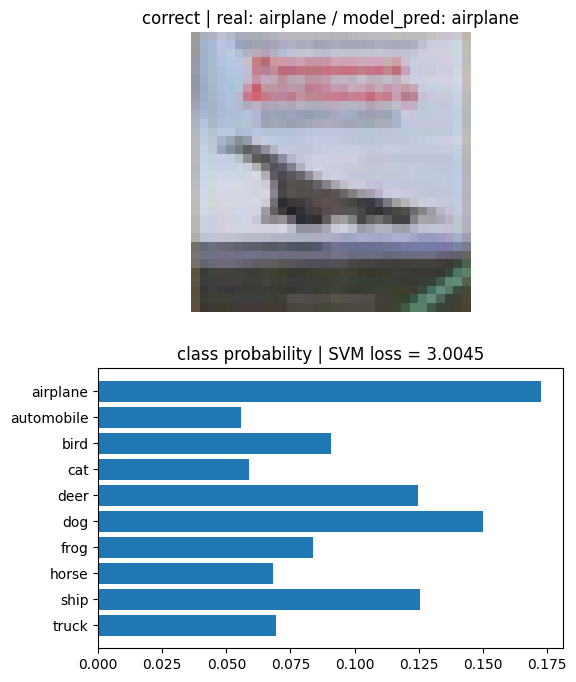

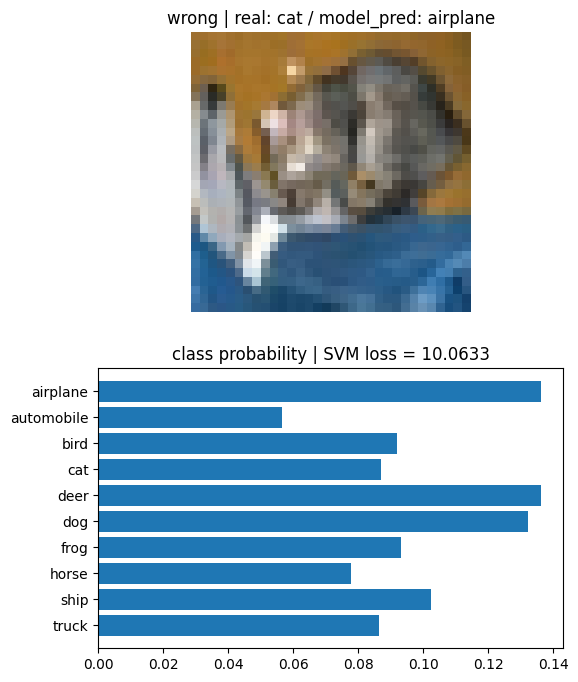

In [73]:
# predict test data
pred_all = linear_pred(X_test, W, b)
label_all = pred_all.argmax(axis=1)
probs_all = softmax(pred_all)

# example
correct_img = np.where(label_all == y_test)[0][0]
wrong_img = np.where(label_all != y_test)[0][0]

for name, i in [('correct', correct_img), ('wrong', wrong_img)]:
    loss_img = svm_loss(pred_all[i:i+1], y_test[i:i+1])[0]   # SVM loss

    fig, (ax_img, ax_bar) = plt.subplots(2, 1, figsize=(6, 8))
    ax_img.imshow(test_images_raw[i])
    ax_img.axis('off')
    ax_img.set_title(f'{name} | real: {class_names[y_test[i]]} / model_pred: {class_names[label_all[i]]}')

    ax_bar.barh(class_names, probs_all[i])
    ax_bar.invert_yaxis()
    ax_bar.set_title(f'class probability | SVM loss = {loss_img:.4f}')
    plt.show()

dog         5033
airplane    3480
deer        1415
ship          46
bird          12
truck          9
frog           3
horse          1
cat            1
Name: count, dtype: int64


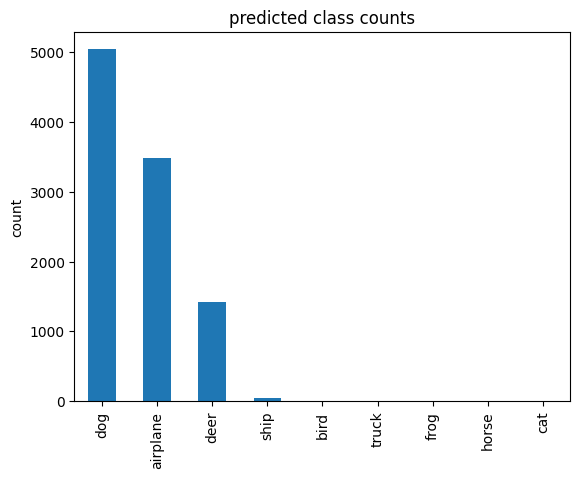

In [67]:
# frequency : check which classes the model predicts for the test data
pred_counts = pd.Series([class_names[i] for i in label_all]).value_counts()
print(pred_counts)

pred_counts.plot(kind='bar')
plt.title('predicted class counts')
plt.ylabel('count')
plt.show()

# Visualize class weights as 32 x 32 x 3 images



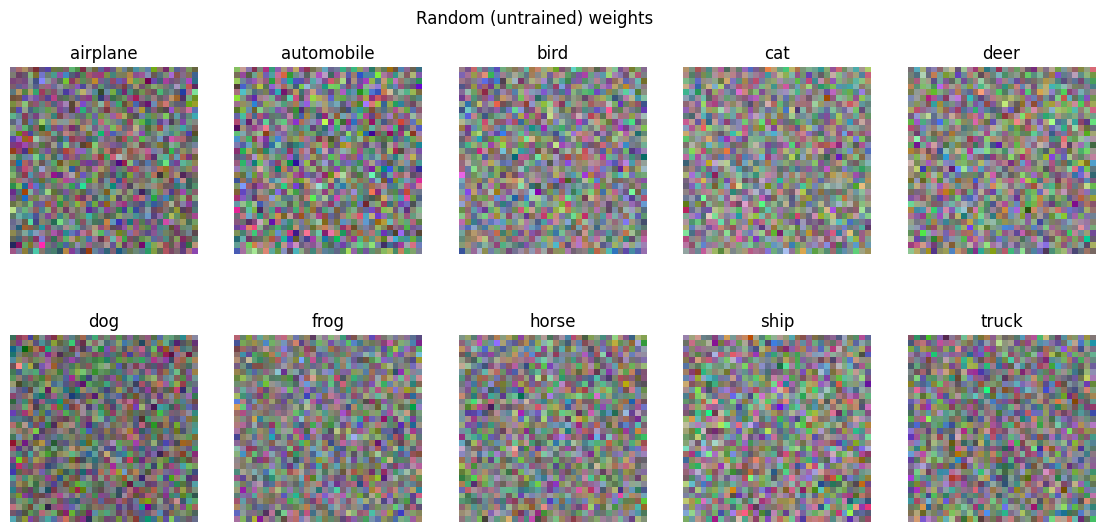

In [68]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for k, ax in enumerate(axes.ravel()):
    w = W[k].reshape(32, 32, 3)
    w = (w - w.min()) / (w.max() - w.min())
    ax.imshow(w)
    ax.set_title(class_names[k])
    ax.axis('off')
fig.suptitle('Random (untrained) weights')
fig.subplots_adjust(hspace=0.3, top=0.9)
plt.show()

- No class-specific shapes or color patterns can be seen in the weight images.
- The random weights W were not optimized in the direction that reduces the loss, so the features of each label do not appear.